# Implementing the Leapfrog Method to Solve an Initial Value Problem

**Name:** S Vignesh  
**Roll Number:** SC26M019

## Problem

The normalized electron plasma oscillation is described by:

dx/dt = v

dv/dt = −ωₚ²x

Here, ωₚ = 1, the initial position is x(0) = 0.5, the initial velocity is v(0) = 0, and the time interval is 0 to 20.

The exact solution is:

Position: x(t) = 0.5 cos(t)

Velocity: v(t) = −0.5 sin(t)

## Question 1: Leapfrog Function

The function evaluates acceleration, updates velocity, and then updates position using the new velocity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x0 = 0.5
v0 = 0
h = 0.1
omega_p = 1

def acceleration(x):
    return -(omega_p**2) * x

def leapfrog(x, v, h):
    a = acceleration(x)
    v_new = v + h * a
    x_new = x + h * v_new
    return x_new, v_new

## Question 2: Initial Half-Step Velocity

The initial velocity is given at time t = 0, but the Leapfrog method stores velocity at half-time levels. Therefore, the starting half-step velocity is calculated as:

v₋₁/₂ = v₀ − (h/2) a(x₀)

In [2]:
v_half = v0 - (h / 2) * acceleration(x0)

print("Initial half-step velocity:", v_half)

x1, v_half = leapfrog(x0, v_half, h)

print("Position after one step:", x1)
print("Velocity at the half-step:", v_half)

Initial half-step velocity: 0.025
Position after one step: 0.4975
Velocity at the half-step: -0.025


## Question 3: Check the Implementation

Integrate from \(t=0\) to \(t=20\) using \(h=0.1\). Position is stored at whole time levels and velocity at half-time levels. The numerical results are compared with the exact solution using the three plots required in the assignment.

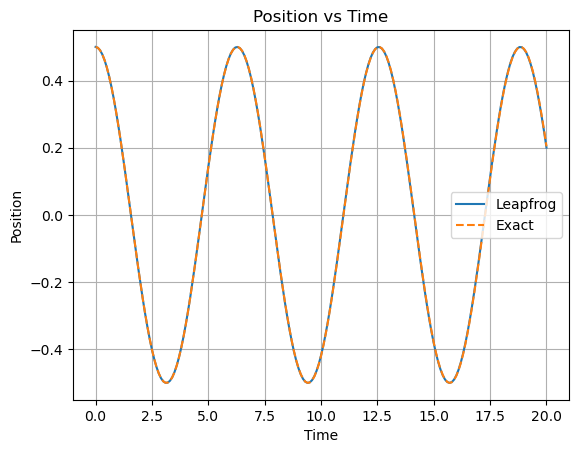

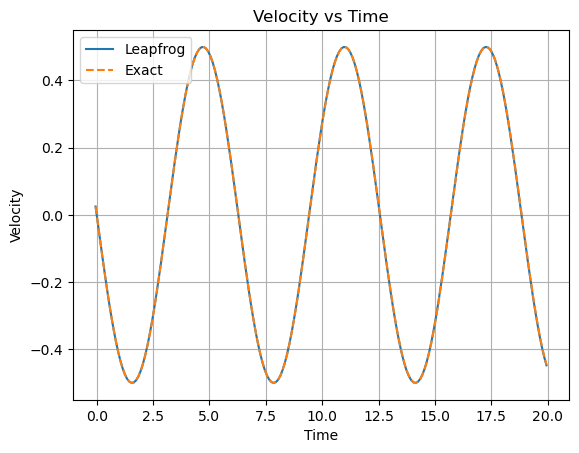

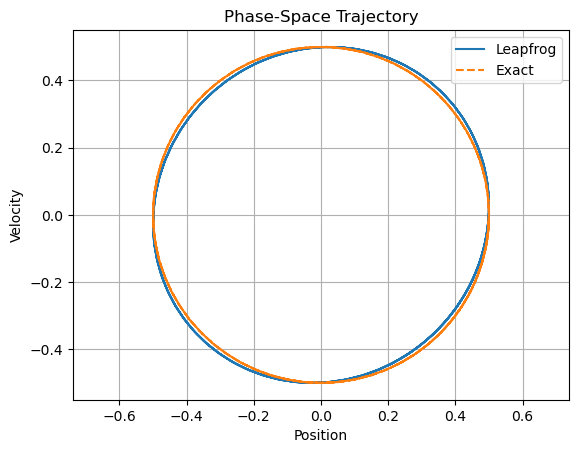

In [3]:
x0 = 0.5
v0 = 0
v_half = v0 - (h / 2) * acceleration(x0)

x_values = [x0]
v_values = [v_half]
t_values = [0]
v_times = [-h / 2]

for i in range(200):
    x0, v_half = leapfrog(x0, v_half, h)
    x_values.append(x0)
    v_values.append(v_half)
    t_values.append((i + 1) * h)
    v_times.append((i + 0.5) * h)

plt.figure()
plt.plot(t_values, x_values, label="Leapfrog")
plt.plot(t_values, 0.5 * np.cos(t_values), "--", label="Exact")
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Position vs Time")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(v_times, v_values, label="Leapfrog")
plt.plot(v_times, -0.5 * np.sin(v_times), "--", label="Exact")
plt.xlabel("Time")
plt.ylabel("Velocity")
plt.title("Velocity vs Time")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(x_values[1:], v_values[1:], label="Leapfrog")
plt.plot(0.5 * np.cos(v_times[1:]), -0.5 * np.sin(v_times[1:]),
         "--", label="Exact")
plt.xlabel("Position")
plt.ylabel("Velocity")
plt.title("Phase-Space Trajectory")
plt.legend()
plt.grid()
plt.axis("equal")
plt.show()

## Question 4: Convergence Study

The maximum position error is calculated for time steps h = 0.2, 0.1, 0.05, and 0.025. The calculation is first performed with the correct staggered initialization and then with the unstaggered initialization, where v₋₁/₂ = v₀.

The observed order is calculated using:

p = log₂[E(h) / E(h/2)]

Correct staggered initialization
h     Maximum Error     Order
0.2 0.015396153502616333 -
0.1 0.0038152808690173623 2.0127
0.05 0.0009516945580628489 2.0032
0.025 0.00023779054510253417 2.0008

Unstaggered initialization
h     Maximum Error     Order
0.2 0.0645570937352627 -
0.1 0.028628279982487917 1.1731
0.05 0.013401662702342016 1.095
0.025 0.0064754034102747 1.0494


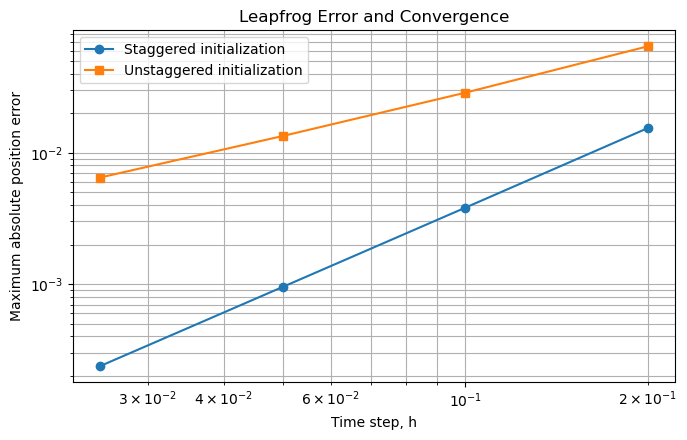

In [4]:
h_values = [0.2, 0.1, 0.05, 0.025]
errors_staggered = []
errors_unstaggered = []

# Correct staggered initialization
for step in h_values:
    x0 = 0.5
    v0 = 0
    v_half = v0 - (step / 2) * acceleration(x0)
    max_error = 0

    for i in range(round(20 / step)):
        x0, v_half = leapfrog(x0, v_half, step)
        t = (i + 1) * step
        error = abs(x0 - 0.5 * np.cos(t))
        if error > max_error:
            max_error = error

    errors_staggered.append(max_error)

# Unstaggered initialization
for step in h_values:
    x0 = 0.5
    v0 = 0
    v_half = v0
    max_error = 0

    for i in range(round(20 / step)):
        x0, v_half = leapfrog(x0, v_half, step)
        t = (i + 1) * step
        error = abs(x0 - 0.5 * np.cos(t))
        if error > max_error:
            max_error = error

    errors_unstaggered.append(max_error)

print("Correct staggered initialization")
print("h     Maximum Error     Order")
for i in range(len(h_values)):
    if i == 0:
        print(h_values[i], errors_staggered[i], "-")
    else:
        p = np.log2(errors_staggered[i - 1] / errors_staggered[i])
        print(h_values[i], errors_staggered[i], round(p, 4))

print()
print("Unstaggered initialization")
print("h     Maximum Error     Order")
for i in range(len(h_values)):
    if i == 0:
        print(h_values[i], errors_unstaggered[i], "-")
    else:
        p = np.log2(errors_unstaggered[i - 1] / errors_unstaggered[i])
        print(h_values[i], errors_unstaggered[i], round(p, 4))

# Line graph: maximum position error against time step
plt.figure(figsize=(7, 4.5))
plt.loglog(h_values, errors_staggered, "o-", label="Staggered initialization")
plt.loglog(h_values, errors_unstaggered, "s-", label="Unstaggered initialization")
plt.xlabel("Time step, h")
plt.ylabel("Maximum absolute position error")
plt.title("Leapfrog Error and Convergence")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


The maximum absolute position error is compared for each time step. The empirical order between two consecutive runs is calculated from

p = log(E(h) / E(h/2)) / log(2)

If halving h reduces the error by about four, p is approximately 2. If it reduces the error by about two, p is approximately 1.

The line graph uses logarithmic scales on both axes. The staggered-initialization curve should fall with an approximate slope of 2, while the unstaggered curve approaches a slope of 1. These are empirical orders for this test problem and these selected time steps. The first row has no order because there is no coarser-step error available for comparison.

## Question 5: Central-Difference Formula

The Leapfrog updates are:

vₙ₊₁/₂ = vₙ₋₁/₂ − hωₚ²xₙ

xₙ₊₁ = xₙ + hvₙ₊₁/₂

Using the position updates to eliminate velocity gives:

xₙ₊₁ − 2xₙ + xₙ₋₁ = −ωₚ²h²xₙ

This can also be written as:

xₙ₊₁ = (2 − ωₚ²h²)xₙ − xₙ₋₁

The central-difference approximation to the second derivative has an error proportional to h². Therefore, the position method is second-order accurate when initialized consistently.

In [5]:
x0 = 0.5
v0 = 0
h = 0.1
t_final = 20
N = round(t_final / h)

v_half = v0 - (h / 2) * acceleration(x0)
x1, v_half = leapfrog(x0, v_half, h)

x_previous = x0
x_current = x1

for i in range(1, N):
    x_next = (2 - omega_p**2 * h**2) * x_current - x_previous
    x_previous = x_current
    x_current = x_next

x_exact = 0.5 * np.cos(t_final)
error = abs(x_current - x_exact)

print("Position at t = 20:", x_current)
print("Exact position:", x_exact)
print("Absolute error:", error)

Position at t = 20: 0.20022575003767834
Exact position: 0.20404103090669598
Absolute error: 0.00381528086901764


## Question 6: Stability Limit

Assume that xₙ = rⁿ in the central-difference recurrence. Substituting this expression gives the characteristic equation:

r² − (2 − ωₚ²h²)r + 1 = 0

The stability condition for this oscillator is:

ωₚh < 2

For values above this limit, one characteristic root has a magnitude greater than 1, so the numerical solution grows. The code tests the four values specified in the assignment.

In [6]:
omega_p = 1
stability_values = [1.9, 1.99, 2.01, 2.1]
N = 100

for value in stability_values:
    h = value / omega_p
    x0 = 0.5
    v0 = 0
    v_half = v0 - (h / 2) * acceleration(x0)
    max_position = abs(x0)

    for i in range(N):
        x0, v_half = leapfrog(x0, v_half, h)
        if abs(x0) > max_position:
            max_position = abs(x0)

    print("omega_p * h:", value)
    print("Time step:", h)
    print("Maximum absolute position:", max_position)

    if value < 2:
        print("Stability condition: Satisfied")
    else:
        print("Stability condition: Violated")

    print()

omega_p * h: 1.9
Time step: 1.9
Maximum absolute position: 0.5
Stability condition: Satisfied

omega_p * h: 1.99
Time step: 1.99
Maximum absolute position: 0.5
Stability condition: Satisfied

omega_p * h: 2.01
Time step: 2.01
Maximum absolute position: 120285863.85725272
Stability condition: Violated

omega_p * h: 2.1
Time step: 2.1
Maximum absolute position: 5.6488079568178676e+26
Stability condition: Violated



For omega_p * h = 1.9 and 1.99, the numerical solution remains bounded. For omega_p * h = 2.01 and 2.1, the numerical solution grows, confirming the stability limit for this oscillator.

The stability condition is omega_p * h < 2. Since omega_p = 1 in this problem, the time step must satisfy h < 2. At the boundary omega_p * h = 2, the characteristic equation has a repeated root; this boundary is not a robust choice for a practical calculation.

### Why this matters in an explicit Particle-in-Cell (PIC) code

In a PIC simulation, charged particles move under electric and magnetic fields computed on a grid. Electrons can oscillate at the electron plasma frequency, omega_pe. If the time step is too large to resolve this fast oscillation, the discrete particle-field update can become numerically unstable: small errors may grow instead of remaining bounded. For the leapfrog oscillator used here, the linear stability requirement is omega_pe * delta_t < 2.

This is a necessary plasma-frequency stability limit for the model, not the only time-step restriction in every PIC implementation. Explicit electromagnetic PIC codes must also satisfy the grid-based electromagnetic Courant (CFL) condition, and practical simulations often choose a smaller time step than the stability limit to obtain adequate accuracy and resolve plasma dynamics. The exact recommended limit depends on the PIC algorithm, grid, and physics being simulated.